# Comparing forecasting models

Which model should you use to forecast your time series: machine learning, a statistical model, a foundation model or a neural network? This guide answers the question with data. The main model families available in skforecast are evaluated with **the same backtesting on three datasets** with different characteristics:

| Family | Model | Forecaster |
|:--|:--|:--|
| Baseline | Seasonal naive | [`ForecasterEquivalentDate`](../api/forecasterequivalentdate.html) |
| Machine learning (linear) | Ridge | [`ForecasterRecursive`](../api/forecasterrecursive.html), [`ForecasterRecursiveMultiSeries`](../api/forecasterrecursivemultiseries.html) |
| Machine learning (trees) | LightGBM | [`ForecasterRecursive`](../api/forecasterrecursive.html), [`ForecasterRecursiveMultiSeries`](../api/forecasterrecursivemultiseries.html) |
| Foundation | Chronos-2 small (zero-shot) | [`ForecasterFoundation`](../api/forecasterfoundation.html) |
| Statistical | AutoARIMA, AutoETS | [`ForecasterStats`](../api/forecasterstats.html) |
| Deep learning | LSTM | [`ForecasterRnn`](../api/forecasterrnn.html) |

For each model, the guide reports the accuracy of the point forecast, the calibration of its 80% prediction interval and the computation time.

## Key takeaways

| Family | Where it stood out in this guide | What to keep in mind |
|:--|:--|:--|
| **Machine learning** (LightGBM, Ridge) | The most accurate model with exogenous variables and several years of history. As a global model, it fits hundreds of series in seconds. | Its accuracy depends on the features (lags, calendar, exogenous variables) and the hyperparameters. Its intervals need out-of-sample residuals to be well calibrated. |
| **Foundation** (Chronos-2) | Close to the best in the three datasets without any training, and the best with the short series. Well calibrated quantiles out of the box. | More compute at prediction time (a GPU is recommended in production). Results on public datasets may be optimistic. |
| **Statistical** (AutoARIMA, AutoETS) | Simple, interpretable and with parametric intervals. With many series, AutoETS is as accurate as the global models. | Behind machine learning and foundation models with exogenous variables (ETS cannot use them) and with the short series, and slower with many series because they fit one model per series. |
| **Deep learning** (LSTM) | Competitive when it learns from many series at once. | Needs plenty of data and tuning: with a single series it is at the level of the baseline or below. |
| **Baseline** (seasonal naive) | The reference: a model that does not beat it is not adding value. | |

**In short**: start with two candidates, a machine learning model with good features and a foundation model, which forecasts without training, and always compare them with a baseline on your own data.

## How the models are compared

+ **Same evaluation**: in each dataset, all the models are evaluated on the same test period with the same [`TimeSeriesFold`](../api/model_selection.html#skforecast.model_selection._split.TimeSeriesFold). Each family has its own [backtesting](backtesting.ipynb) function, but the partitions are identical. The models are trained once on the training set, without refitting between folds; Chronos-2, which is not trained, receives as context all the observations before each fold. It is used in its small version (`autogluon/chronos-2-small`, the default in skforecast), which runs fast on CPU; the base version (`autogluon/chronos-2`) is larger.

+ **No tuning on the test set**: each model uses a reasonable configuration (lags, features, hyperparameters, network size), fixed in advance and not searched on the test period. It is not the best possible configuration for each dataset: tuning it on a validation period, as shown in [hyperparameter tuning](hyperparameter-tuning-and-lags-selection.ipynb), can improve any of the models.

+ **Prediction intervals of 80%**: each family uses its natural method. Conformal prediction with the out-of-sample residuals of a backtest before the test period for Ridge and LightGBM in the first two datasets, conformal prediction with in-sample residuals for the global models of the tourism dataset, the seasonal naive and the LSTM, the parametric intervals of ARIMA and ETS and the 0.1 and 0.9 quantiles of Chronos-2. See [probabilistic forecasting](probabilistic-forecasting-overview.md).

+ **Metrics**: MAE, MASE (the MAE divided by the MAE of the one-step naive forecast in the training set: lower is better and, being scale free, it can be compared across datasets and series), coverage of the interval (the closer to 80%, the better calibrated) and the time of the whole backtesting, on CPU. The first time ARIMA and ETS run in a new environment, numba compiles them once (a few seconds); the times shown were measured after that compilation.

In [1]:
# Libraries
# ==============================================================================
import os
os.environ["KERAS_BACKEND"] = "torch"  # 'tensorflow', 'jax' or 'torch'
os.environ["KERAS_TORCH_DEVICE"] = "cpu"  # All the models run on CPU, so the times are comparable
import time
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from lightgbm import LGBMRegressor

import skforecast
from skforecast.datasets import fetch_dataset, load_demo_dataset
from skforecast.recursive import (
    ForecasterEquivalentDate,
    ForecasterRecursive,
    ForecasterRecursiveMultiSeries,
    ForecasterStats,
)
from skforecast.stats import Arima, Ets
from skforecast.foundation import FoundationModel, ForecasterFoundation
from skforecast.deep_learning import ForecasterRnn, create_and_compile_model
from skforecast.preprocessing import RollingFeatures, CalendarFeatures
from skforecast.model_selection import (
    TimeSeriesFold,
    backtesting_forecaster,
    backtesting_forecaster_multiseries,
    backtesting_stats,
    backtesting_foundation,
)
from skforecast.metrics import mean_absolute_scaled_error, calculate_coverage
from skforecast.plot import set_dark_theme, plot_prediction_intervals

set_dark_theme()
warnings.filterwarnings("ignore", message="Skipping variable loading for optimizer")

The backtesting predictions of every model are stored in a dictionary, with the same column names (`pred`, `lower_bound`, `upper_bound` and, for several series, `level`). Two small functions compute the metrics and plot the predictions from that dictionary.

In [2]:
# Functions to summarize and plot the backtesting predictions
# ==============================================================================
def summarize(predictions, elapsed, series, n_train):
    """
    MAE, MASE, interval coverage and time of each model. MAE and coverage are
    computed over all the predicted values, MASE is the average of the series.
    """
    results = {}
    for model, pred in predictions.items():
        if "level" not in pred.columns:
            pred = pred.assign(level=series.columns[0])
        y_true = pd.concat(
            [series.loc[p.index, level] for level, p in pred.groupby("level")]
        )
        pred = pd.concat([p for _, p in pred.groupby("level")])
        mase = [
            mean_absolute_scaled_error(
                y_true=series.loc[p.index, level],
                y_pred=p["pred"],
                y_train=series[level].iloc[:n_train],
            )
            for level, p in pred.groupby("level")
        ]
        results[model] = {
            "MAE": np.mean(np.abs(y_true.to_numpy() - pred["pred"].to_numpy())),
            "MASE": np.mean(mase),
            "Coverage (80%)": calculate_coverage(
                y_true.to_numpy(),
                pred["lower_bound"].to_numpy(),
                pred["upper_bound"].to_numpy(),
            ),
            "Time (s)": elapsed[model],
        }

    return pd.DataFrame(results).T.sort_values("MASE")


# Order of the models in tables and figures
models = ["Seasonal naive", "Ridge", "LightGBM", "Chronos-2", "ARIMA", "ETS", "LSTM"]


def plot_predictions(predictions, series, level, title):
    """
    One panel per model with its backtesting predictions and interval.
    """
    fig, axes = plt.subplots(2, 4, figsize=(11, 4.5), sharex=True, sharey=True)
    for ax, model in zip(axes.flat, models):
        pred = predictions[model]
        if "level" in pred.columns:
            pred = pred.loc[pred["level"] == level]
        plot_prediction_intervals(
            predictions=pred, y_true=series, target_variable=level, title=model,
            kwargs_fill_between={"color": "white", "alpha": 0.25, "zorder": 1}, ax=ax,
        )
        ax.get_legend().remove()
    handles, labels = axes.flat[0].get_legend_handles_labels()
    axes.flat[-1].axis("off")
    axes.flat[-1].legend(handles, labels, loc="center", frameon=False)
    fig.suptitle(title)
    fig.tight_layout()

## Which model wins with exogenous variables?

Daily electricity demand in Victoria (Australia) from 2012 to 2014, with the maximum and mean temperature and the holidays as exogenous variables. The demand has a weekly and a yearly seasonality and depends strongly on the temperature. The last 56 days are predicted in 2 folds of 28 days.

In [3]:
# Download data and aggregate it to daily values
# ==============================================================================
data = fetch_dataset(name="vic_electricity")
data["Date"] = pd.to_datetime(data["Date"])
data = data.groupby("Date").agg(
    demand=("Demand", "sum"),
    temp_max=("Temperature", "max"),
    temp_mean=("Temperature", "mean"),
    holiday=("Holiday", "max"),
)
data = data.loc["2012-01-01":"2014-12-31"].asfreq("D")
data.index.name = None
data["demand"] = data["demand"] / 1000  # MWh to GWh
data["holiday"] = data["holiday"].astype(float)
data.head(3)

╭──────────────────────────── vic_electricity ─────────────────────────────╮
│ Description:                                                             │
│ Half-hourly electricity demand for Victoria, Australia                   │
│                                                                          │
│ Source:                                                                  │
│ O'Hara-Wild M, Hyndman R, Wang E, Godahewa R (2022).tsibbledata: Diverse │
│ Datasets for 'tsibble'. https://tsibbledata.tidyverts.org/,              │
│ https://github.com/tidyverts/tsibbledata/.                               │
│ https://tsibbledata.tidyverts.org/reference/vic_elec.html                │
│                                                                          │
│ URL:                                                                     │
│ https://raw.githubusercontent.com/skforecast/skforecast-                 │
│ datasets/main/data/vic_electricity.csv                                   │
│                                                                          │
│ Shape: 52608 rows x 4 columns                                            │
╰──────────────────────────────────────────────────────────────────────────╯

,demand,temp_max,temp_mean,holiday
2012-01-01,222.437912,32.7,25.322917,1.0
2012-01-02,257.964724,39.6,30.689583,1.0
2012-01-03,267.098605,31.8,26.513542,0.0


Train dates : 2012-01-01 --- 2014-11-05  (n=1040)
Test dates  : 2014-11-06 --- 2014-12-31  (n=56)


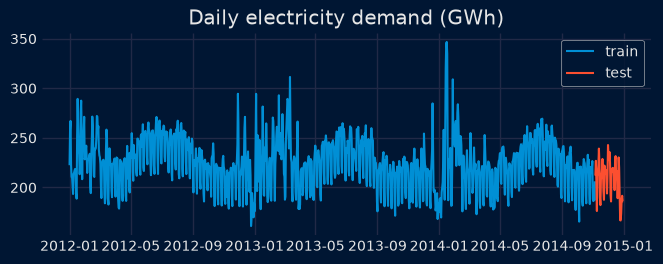

In [4]:
# Split data into train-test and backtesting partitions
# ==============================================================================
y = data["demand"]
exog = data[["temp_max", "temp_mean", "holiday"]]
n_train = len(data) - 56
print(f"Train dates : {data.index[0].date()} --- {data.index[n_train - 1].date()}  (n={n_train})")
print(f"Test dates  : {data.index[n_train].date()} --- {data.index[-1].date()}  (n={len(data) - n_train})")

cv = TimeSeriesFold(steps=28, initial_train_size=n_train, refit=False, verbose=False)

fig, ax = plt.subplots(figsize=(7, 2.5))
ax.plot(y.iloc[:n_train], label="train")
ax.plot(y.iloc[n_train:], label="test")
ax.set_title("Daily electricity demand (GWh)")
ax.legend();

In [5]:
# Seasonal naive: the value of the same day of the previous week
# ==============================================================================
predictions, elapsed = {}, {}

start = time.perf_counter()
forecaster = ForecasterEquivalentDate(offset=7)
_, predictions["Seasonal naive"] = backtesting_forecaster(
    forecaster=forecaster, y=y, cv=cv, metric="mean_absolute_error",
    interval=[0.1, 0.9], interval_method="conformal", use_binned_residuals=False,
    show_progress=False,
)
elapsed["Seasonal naive"] = time.perf_counter() - start

In [6]:
# Machine learning: Ridge and LightGBM with lags, rolling mean, calendar features
# and exogenous variables. Intervals use the out-of-sample residuals of a backtest
# over the year before the test period.
# ==============================================================================
cv_calibration = TimeSeriesFold(
    steps=28, initial_train_size=n_train - 365, refit=False, verbose=False
)
estimators = {
    "Ridge": Ridge(),
    "LightGBM": LGBMRegressor(
        n_estimators=400, learning_rate=0.03, num_leaves=15, random_state=123, verbose=-1
    ),
}
for model, estimator in estimators.items():
    start = time.perf_counter()
    forecaster = ForecasterRecursive(
        estimator=estimator,
        lags=7,
        window_features=RollingFeatures(stats="mean", window_sizes=7),
        calendar_features=CalendarFeatures(features=["day_of_week", "day_of_year"]),
        transformer_y=StandardScaler(),
        transformer_exog=StandardScaler(),
    )
    _, pred_calibration = backtesting_forecaster(
        forecaster=forecaster, y=y.iloc[:n_train], exog=exog.iloc[:n_train],
        cv=cv_calibration, metric="mean_absolute_error", show_progress=False,
    )
    forecaster.fit(y=y.iloc[:n_train], exog=exog.iloc[:n_train])
    forecaster.set_out_sample_residuals(
        y_true=y.loc[pred_calibration.index], y_pred=pred_calibration["pred"]
    )
    _, predictions[model] = backtesting_forecaster(
        forecaster=forecaster, y=y, exog=exog, cv=cv, metric="mean_absolute_error",
        interval=[0.1, 0.9], interval_method="conformal",
        use_in_sample_residuals=False, use_binned_residuals=False, show_progress=False,
    )
    elapsed[model] = time.perf_counter() - start

In [7]:
# Statistical: AutoARIMA with weekly seasonality and exogenous variables, and
# AutoETS with weekly seasonality (ETS does not use exogenous variables)
# ==============================================================================
start = time.perf_counter()
forecaster = ForecasterStats(estimator=Arima(order=None, seasonal_order=None, m=7))
_, predictions["ARIMA"] = backtesting_stats(
    forecaster=forecaster, y=y, exog=exog, cv=cv, metric="mean_absolute_error",
    interval=[0.1, 0.9], show_progress=False, suppress_warnings=True,
)
elapsed["ARIMA"] = time.perf_counter() - start

start = time.perf_counter()
forecaster = ForecasterStats(estimator=Ets(m=7))
_, predictions["ETS"] = backtesting_stats(
    forecaster=forecaster, y=y, cv=cv, metric="mean_absolute_error",
    interval=[0.1, 0.9], show_progress=False, suppress_warnings=True,
)
elapsed["ETS"] = time.perf_counter() - start

In [8]:
# Foundation: Chronos-2 zero-shot, with the exogenous variables as covariates
# ==============================================================================
start = time.perf_counter()
forecaster = ForecasterFoundation(estimator=FoundationModel("autogluon/chronos-2-small", device_map="cpu"))
_, pred = backtesting_foundation(
    forecaster=forecaster, series=y, exog=exog, cv=cv, metric="mean_absolute_error",
    quantiles=[0.1, 0.5, 0.9], show_progress=False,
)
predictions["Chronos-2"] = pred.rename(
    columns={"q_0.1": "lower_bound", "q_0.5": "pred", "q_0.9": "upper_bound"}
)
elapsed["Chronos-2"] = time.perf_counter() - start

Loading weights: 100%|██████████| 92/92 [00:00<00:00, 5511.33it/s]

In [9]:
# Deep learning: LSTM network that predicts the 28 days of each fold at once
# ==============================================================================
start = time.perf_counter()
keras.utils.set_random_seed(123)
network = create_and_compile_model(
    series=data[["demand"]], exog=exog, levels=["demand"], lags=28, steps=28,
    recurrent_layer="LSTM", recurrent_units=32, dense_units=16,
)
forecaster = ForecasterRnn(
    estimator=network, levels=["demand"], lags=28,
    fit_kwargs={"epochs": 50, "batch_size": 32, "verbose": 0},
)
_, predictions["LSTM"] = backtesting_forecaster_multiseries(
    forecaster=forecaster, series=data[["demand"]], exog=exog, cv=cv,
    metric="mean_absolute_error", interval=[0.1, 0.9], use_binned_residuals=False,
    show_progress=False,
)
elapsed["LSTM"] = time.perf_counter() - start

keras version: 3.14.0
Using backend: torch
torch version: 2.14.0

Using 'torch' backend with device: mps


In [10]:
# Results
# ==============================================================================
results_electricity = summarize(predictions, elapsed, data[["demand"]], n_train)
results_electricity.style.format(precision=2).highlight_min(subset=["MASE"], color="green")

,MAE,MASE,Coverage (80%),Time (s)
LightGBM,5.17,0.33,0.95,2.10
Chronos-2,5.86,0.38,0.88,5.36
Ridge,8.70,0.56,0.91,0.04
ARIMA,11.39,0.73,0.88,1.19
LSTM,15.72,1.01,0.79,19.60
Seasonal naive,16.97,1.09,0.70,0.07
ETS,17.27,1.11,0.96,1.14


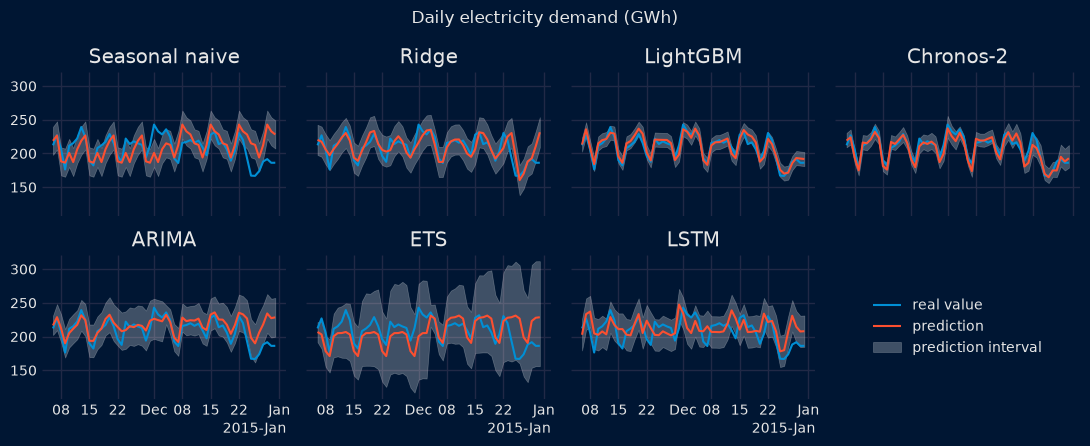

In [11]:
# Backtesting predictions
# ==============================================================================
plot_predictions(predictions, data, level="demand", title="Daily electricity demand (GWh)")

+ LightGBM, with lags, calendar features and the temperature, is the most accurate model. Chronos-2 comes close without any training, using the temperature and the holidays as covariates.

+ The features carry most of the information: the models that cannot use the temperature (ETS) or that learn from a single series with little data (LSTM) are at the level of the baseline.

+ With out-of-sample residuals, the intervals of the machine learning models reach the nominal coverage or exceed it. The interval of ETS, which does not use the temperature, is very wide.

## What if the series is short?

Monthly expenditure on corticosteroid drugs in Australia (`h2o` dataset): only 204 observations, with trend and yearly seasonality and no exogenous variables. The last 36 months are predicted in 3 folds of 12 months.

╭────────────────────────────────────── h2o ───────────────────────────────────────╮
│ Description:                                                                     │
│ Monthly expenditure ($AUD) on corticosteroid drugs that the Australian health    │
│ system had between 1991 and 2008.                                                │
│                                                                                  │
│ Source:                                                                          │
│ Hyndman R (2023). fpp3: Data for Forecasting: Principles and Practice(3rd        │
│ Edition). http://pkg.robjhyndman.com/fpp3package/,https://github.com/robjhyndman │
│ /fpp3package, http://OTexts.com/fpp3.                                            │
│                                                                                  │
│ URL:                                                                             │
│ https://raw.githubusercontent.com/skforecast/skforecast-                         │
│ datasets/main/data/h2o.csv                                                       │
│                                                                                  │
│ Shape: 204 rows                                                                  │
╰──────────────────────────────────────────────────────────────────────────────────╯

Train dates : 1991-07-01 --- 2005-06-01  (n=168)
Test dates  : 2005-07-01 --- 2008-06-01  (n=36)


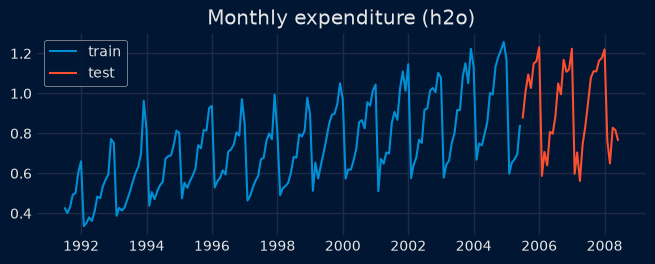

In [12]:
# Download data, split into train-test and backtesting partitions
# ==============================================================================
y = load_demo_dataset()
y.name = "y"
n_train = len(y) - 36
print(f"Train dates : {y.index[0].date()} --- {y.index[n_train - 1].date()}  (n={n_train})")
print(f"Test dates  : {y.index[n_train].date()} --- {y.index[-1].date()}  (n={len(y) - n_train})")

cv = TimeSeriesFold(steps=12, initial_train_size=n_train, refit=False, verbose=False)

fig, ax = plt.subplots(figsize=(7, 2.5))
ax.plot(y.iloc[:n_train], label="train")
ax.plot(y.iloc[n_train:], label="test")
ax.set_title("Monthly expenditure (h2o)")
ax.legend();

In [13]:
# Seasonal naive: the value of the same month of the previous year
# ==============================================================================
predictions, elapsed = {}, {}

start = time.perf_counter()
forecaster = ForecasterEquivalentDate(offset=12)
_, predictions["Seasonal naive"] = backtesting_forecaster(
    forecaster=forecaster, y=y, cv=cv, metric="mean_absolute_error",
    interval=[0.1, 0.9], interval_method="conformal", use_binned_residuals=False,
    show_progress=False,
)
elapsed["Seasonal naive"] = time.perf_counter() - start

In [14]:
# Machine learning: Ridge and LightGBM with 24 lags and the month. Intervals use
# the out-of-sample residuals of a backtest over the 3 years before the test period.
# ==============================================================================
cv_calibration = TimeSeriesFold(
    steps=12, initial_train_size=n_train - 36, refit=False, verbose=False
)
estimators = {
    "Ridge": Ridge(),
    "LightGBM": LGBMRegressor(
        n_estimators=200, learning_rate=0.05, max_depth=4, random_state=123, verbose=-1
    ),
}
for model, estimator in estimators.items():
    start = time.perf_counter()
    forecaster = ForecasterRecursive(
        estimator=estimator,
        lags=24,
        calendar_features=CalendarFeatures(features=["month"]),
        transformer_y=StandardScaler(),
        binner_kwargs={"n_bins": 3},  # Few calibration residuals to store by bin
    )
    _, pred_calibration = backtesting_forecaster(
        forecaster=forecaster, y=y.iloc[:n_train], cv=cv_calibration,
        metric="mean_absolute_error", show_progress=False,
    )
    forecaster.fit(y=y.iloc[:n_train])
    forecaster.set_out_sample_residuals(
        y_true=y.loc[pred_calibration.index], y_pred=pred_calibration["pred"]
    )
    _, predictions[model] = backtesting_forecaster(
        forecaster=forecaster, y=y, cv=cv, metric="mean_absolute_error",
        interval=[0.1, 0.9], interval_method="conformal",
        use_in_sample_residuals=False, use_binned_residuals=False, show_progress=False,
    )
    elapsed[model] = time.perf_counter() - start

In [15]:
# Statistical: AutoARIMA and AutoETS with yearly seasonality
# ==============================================================================
statistical = {
    "ARIMA": Arima(order=None, seasonal_order=None, m=12),
    "ETS": Ets(m=12),
}
for model, estimator in statistical.items():
    start = time.perf_counter()
    _, predictions[model] = backtesting_stats(
        forecaster=ForecasterStats(estimator=estimator), y=y, cv=cv,
        metric="mean_absolute_error", interval=[0.1, 0.9],
        show_progress=False, suppress_warnings=True,
    )
    elapsed[model] = time.perf_counter() - start

In [16]:
# Foundation: Chronos-2 zero-shot
# ==============================================================================
start = time.perf_counter()
forecaster = ForecasterFoundation(estimator=FoundationModel("autogluon/chronos-2-small", device_map="cpu"))
_, pred = backtesting_foundation(
    forecaster=forecaster, series=y, cv=cv, metric="mean_absolute_error",
    quantiles=[0.1, 0.5, 0.9], show_progress=False,
)
predictions["Chronos-2"] = pred.rename(
    columns={"q_0.1": "lower_bound", "q_0.5": "pred", "q_0.9": "upper_bound"}
)
elapsed["Chronos-2"] = time.perf_counter() - start

Loading weights: 100%|██████████| 92/92 [00:00<00:00, 4336.51it/s]

In [17]:
# Deep learning: LSTM network that predicts the 12 months of each fold at once
# ==============================================================================
start = time.perf_counter()
keras.utils.set_random_seed(123)
network = create_and_compile_model(
    series=y.to_frame(), levels=["y"], lags=24, steps=12,
    recurrent_layer="LSTM", recurrent_units=64, dense_units=16,
)
forecaster = ForecasterRnn(
    estimator=network, levels=["y"], lags=24,
    fit_kwargs={"epochs": 100, "batch_size": 16, "verbose": 0},
)
_, predictions["LSTM"] = backtesting_forecaster_multiseries(
    forecaster=forecaster, series=y.to_frame(), cv=cv,
    metric="mean_absolute_error", interval=[0.1, 0.9], use_binned_residuals=False,
    show_progress=False,
)
elapsed["LSTM"] = time.perf_counter() - start

keras version: 3.14.0
Using backend: torch
torch version: 2.14.0

Using 'torch' backend with device: mps


In [18]:
# Results
# ==============================================================================
results_short = summarize(predictions, elapsed, y.to_frame(), n_train)
results_short.style.format(precision=3).highlight_min(subset=["MASE"], color="green")

,MAE,MASE,Coverage (80%),Time (s)
Chronos-2,0.054,0.587,0.778,1.287
LightGBM,0.061,0.668,0.944,0.312
Ridge,0.064,0.696,0.778,0.013
Seasonal naive,0.067,0.727,0.750,0.002
ETS,0.068,0.743,0.750,0.372
ARIMA,0.069,0.748,0.583,0.736
LSTM,0.089,0.973,0.667,6.303


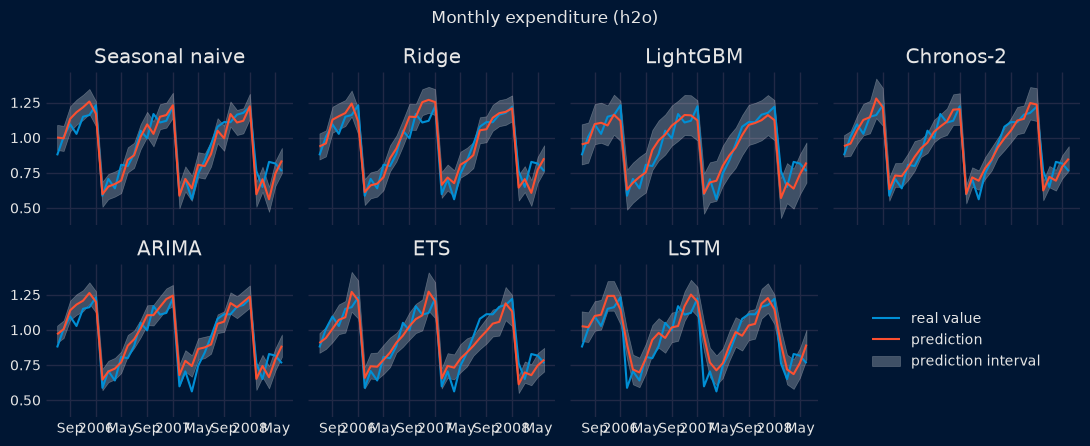

In [19]:
# Backtesting predictions
# ==============================================================================
plot_predictions(predictions, y.to_frame(), level="y", title="Monthly expenditure (h2o)")

+ With little history, the pre-trained knowledge of Chronos-2 makes the difference: it is the most accurate model without any training.

+ The machine learning models, with lags and the month as features, come next. The statistical models are at the level of the seasonal naive.

+ The LSTM is the least accurate model: a neural network needs more data than a single short series provides.

## Many series: one global model or one model per series?

Quarterly overnight trips in Australia from 1998 to 2017, by region and purpose of travel: 304 series of 80 observations. Ridge, LightGBM, Chronos-2 and the LSTM are global models: a single model forecasts all the series. The seasonal naive, ARIMA and ETS are local models: one model is fitted for each series. The last 8 quarters are predicted in 2 folds of 4 quarters.

In [20]:
# Download data, split into train-test and backtesting partitions
# ==============================================================================
data = fetch_dataset(name="australia_tourism")
data["series"] = data["Region"] + " - " + data["Purpose"]
series = data.pivot_table(index=data.index, columns="series", values="Trips").asfreq("QS")
series.index.name = None
series.columns.name = None
n_train = len(series) - 8
print(f"Number of series: {series.shape[1]}")
print(f"Train dates     : {series.index[0].date()} --- {series.index[n_train - 1].date()}  (n={n_train})")
print(f"Test dates      : {series.index[n_train].date()} --- {series.index[-1].date()}  (n={len(series) - n_train})")

series_dict = series.to_dict(orient="series")  # Input format recommended for global models
cv = TimeSeriesFold(steps=4, initial_train_size=n_train, refit=False, verbose=False)
series.iloc[:3, :4]

╭─────────────────────────────── australia_tourism ────────────────────────────────╮
│ Description:                                                                     │
│ Quarterly overnight trips (in thousands) from 1998 Q1 to 2016 Q4 across          │
│ Australia. The tourism regions are formed through the aggregation of Statistical │
│ Local Areas (SLAs) which are defined by the various State and Territory tourism  │
│ authorities according to their research and marketing needs.                     │
│                                                                                  │
│ Source:                                                                          │
│ Wang, E, D Cook, and RJ Hyndman (2020). A new tidy data structure to support     │
│ exploration and modeling of temporal data, Journal of Computational and          │
│ Graphical Statistics, 29:3, 466-478, doi:10.1080/10618600.2019.1695624.          │
│                                                                                  │
│ URL:                                                                             │
│ https://raw.githubusercontent.com/skforecast/skforecast-                         │
│ datasets/main/data/australia_tourism.csv                                         │
│                                                                                  │
│ Shape: 24320 rows x 4 columns                                                    │
╰──────────────────────────────────────────────────────────────────────────────────╯

Number of series: 304
Train dates     : 1998-01-01 --- 2015-10-01  (n=72)
Test dates      : 2016-01-01 --- 2017-10-01  (n=8)


,Adelaide - Business,Adelaide - Holiday,Adelaide - Other,Adelaide - Visiting
1998-01-01,135.077690,223.557406,58.362689,241.556109
1998-04-01,109.987316,130.287369,39.468735,170.110514
1998-07-01,166.034687,156.089398,38.431629,232.348883


In [21]:
# Local models: one seasonal naive, one AutoARIMA and one AutoETS for each series
# ==============================================================================
predictions, elapsed = {}, {}

start = time.perf_counter()
pred_series = []
for level in series.columns:
    _, pred = backtesting_forecaster(
        forecaster=ForecasterEquivalentDate(offset=4), y=series[level], cv=cv,
        metric="mean_absolute_error", interval=[0.1, 0.9],
        interval_method="conformal", use_binned_residuals=False, show_progress=False,
    )
    pred_series.append(pred.assign(level=level))
predictions["Seasonal naive"] = pd.concat(pred_series)
elapsed["Seasonal naive"] = time.perf_counter() - start

statistical = {
    "ARIMA": Arima(order=None, seasonal_order=None, m=4),
    "ETS": Ets(m=4),
}
for model, estimator in statistical.items():
    start = time.perf_counter()
    pred_series = []
    for level in series.columns:
        _, pred = backtesting_stats(
            forecaster=ForecasterStats(estimator=estimator),
            y=series[level], cv=cv, metric="mean_absolute_error", interval=[0.1, 0.9],
            show_progress=False, suppress_warnings=True,
        )
        pred_series.append(pred.assign(level=level))
    predictions[model] = pd.concat(pred_series)
    elapsed[model] = time.perf_counter() - start

In [22]:
# Global machine learning: Ridge and LightGBM trained on the 304 series
# ==============================================================================
start = time.perf_counter()
forecaster = ForecasterRecursiveMultiSeries(
    estimator=Ridge(),
    lags=8,
    window_features=RollingFeatures(stats="mean", window_sizes=4),
    calendar_features=CalendarFeatures(features=["quarter"], encoding="onehot"),
    encoding=None,
    transformer_series=StandardScaler(),
)
_, predictions["Ridge"] = backtesting_forecaster_multiseries(
    forecaster=forecaster, series=series_dict, cv=cv, metric="mean_absolute_error",
    interval=[0.1, 0.9], use_binned_residuals=False, show_progress=False,
)
elapsed["Ridge"] = time.perf_counter() - start

start = time.perf_counter()
forecaster = ForecasterRecursiveMultiSeries(
    estimator=LGBMRegressor(
        n_estimators=300, learning_rate=0.05, num_leaves=15, random_state=123, verbose=-1
    ),
    lags=8,
    window_features=RollingFeatures(stats="mean", window_sizes=4),
    calendar_features=CalendarFeatures(features=["quarter"]),
    encoding="ordinal",
)
_, predictions["LightGBM"] = backtesting_forecaster_multiseries(
    forecaster=forecaster, series=series_dict, cv=cv, metric="mean_absolute_error",
    interval=[0.1, 0.9], use_binned_residuals=False, show_progress=False,
)
elapsed["LightGBM"] = time.perf_counter() - start

In [23]:
# Foundation: Chronos-2 zero-shot on the 304 series
# ==============================================================================
start = time.perf_counter()
forecaster = ForecasterFoundation(estimator=FoundationModel("autogluon/chronos-2-small", device_map="cpu"))
_, pred = backtesting_foundation(
    forecaster=forecaster, series=series_dict, cv=cv, metric="mean_absolute_error",
    quantiles=[0.1, 0.5, 0.9], show_progress=False,
)
predictions["Chronos-2"] = pred.rename(
    columns={"q_0.1": "lower_bound", "q_0.5": "pred", "q_0.9": "upper_bound"}
)
elapsed["Chronos-2"] = time.perf_counter() - start

Loading weights: 100%|██████████| 92/92 [00:00<00:00, 4782.20it/s]

In [24]:
# Deep learning: one LSTM network that predicts the 304 series at once
# ==============================================================================
start = time.perf_counter()
keras.utils.set_random_seed(123)
network = create_and_compile_model(
    series=series, levels=list(series.columns), lags=8, steps=4,
    recurrent_layer="LSTM", recurrent_units=64, dense_units=64,
)
forecaster = ForecasterRnn(
    estimator=network, levels=list(series.columns), lags=8,
    fit_kwargs={"epochs": 100, "batch_size": 16, "verbose": 0},
)
_, predictions["LSTM"] = backtesting_forecaster_multiseries(
    forecaster=forecaster, series=series, cv=cv, metric="mean_absolute_error",
    interval=[0.1, 0.9], use_binned_residuals=False, show_progress=False,
)
elapsed["LSTM"] = time.perf_counter() - start

keras version: 3.14.0
Using backend: torch
torch version: 2.14.0

Using 'torch' backend with device: mps


In [25]:
# Results
# ==============================================================================
results_many = summarize(predictions, elapsed, series, n_train)
results_many.style.format(precision=2).highlight_min(subset=["MASE"], color="green")

,MAE,MASE,Coverage (80%),Time (s)
LSTM,14.83,0.85,0.60,2.15
ETS,15.24,0.87,0.75,29.43
Ridge,14.63,0.87,0.78,1.90
LightGBM,15.02,0.87,0.70,1.02
ARIMA,15.84,0.88,0.73,90.90
Chronos-2,15.85,0.88,0.76,1.74
Seasonal naive,16.95,1.02,0.74,0.33


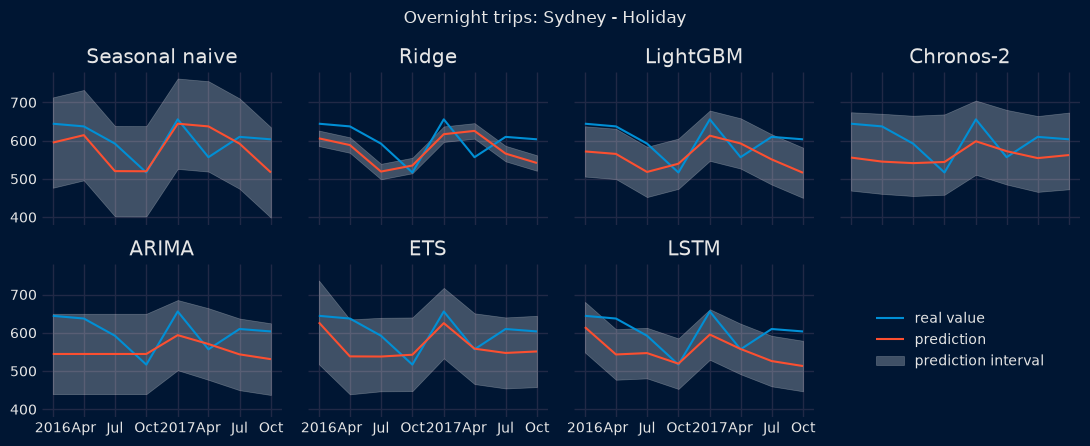

In [26]:
# Backtesting predictions of one of the series
# ==============================================================================
level = "Sydney - Holiday"
plot_predictions(predictions, series, level=level, title=f"Overnight trips: {level}")

+ Apart from the seasonal naive, all the models reach a similar accuracy: the differences between them are small enough to change with another test period.

+ The coverage varies more than the accuracy. The intervals built from in-sample residuals tend to be too narrow, more so for the models that fit the training data closely (LightGBM, LSTM), because the in-sample residuals are smaller than the errors on new data.

+ The difference is the cost: a global model (machine learning, Chronos-2 or the LSTM) forecasts all the series at once, much faster than fitting one AutoARIMA or AutoETS per series.

## Summary: accuracy and computation time

The heatmap shows the MASE of each model in the three datasets (lower is better, the best model of each dataset is highlighted). The scatter plot puts the accuracy next to the cost: the time of the whole backtesting, on a logarithmic scale.

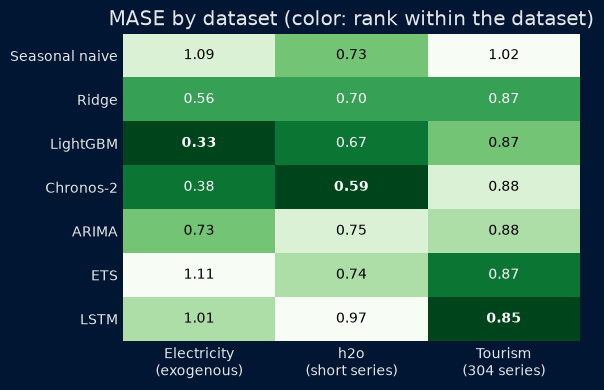

In [27]:
# MASE of each model in each dataset
# ==============================================================================
datasets = {
    "Electricity\n(exogenous)": results_electricity,
    "h2o\n(short series)": results_short,
    "Tourism\n(304 series)": results_many,
}
mase = pd.DataFrame({name: results["MASE"] for name, results in datasets.items()}).loc[models]
rank = mase.rank(axis=0)

fig, ax = plt.subplots(figsize=(6, 4))
ax.imshow(rank.to_numpy(), cmap="Greens_r", vmin=1, vmax=len(models), aspect="auto")
for (i, j), value in np.ndenumerate(mase.to_numpy()):
    ax.text(j, i, f"{value:.2f}", ha="center", va="center",
            fontweight="bold" if rank.iloc[i, j] == 1 else "normal",
            color="white" if rank.iloc[i, j] <= 3 else "black")
ax.set_xticks(range(mase.shape[1]), mase.columns)
ax.set_yticks(range(mase.shape[0]), mase.index)
ax.grid(False)
ax.set_title("MASE by dataset (color: rank within the dataset)")
fig.tight_layout()

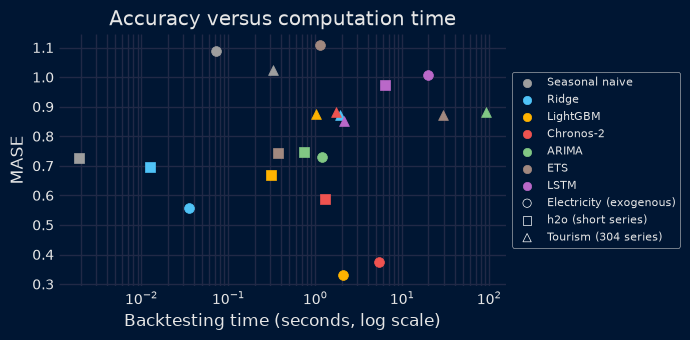

In [28]:
# Accuracy versus computation time
# ==============================================================================
colors = {
    "Seasonal naive": "#9e9e9e", "Ridge": "#4fc3f7", "LightGBM": "#ffb300",
    "Chronos-2": "#ef5350", "ARIMA": "#81c784", "ETS": "#a1887f", "LSTM": "#ba68c8",
}
markers = ["o", "s", "^"]

fig, ax = plt.subplots(figsize=(7, 3.5))
for (name, results), marker in zip(datasets.items(), markers):
    for model in models:
        ax.scatter(results.loc[model, "Time (s)"], results.loc[model, "MASE"],
                   marker=marker, color=colors[model], s=50)
for model in models:
    ax.scatter([], [], color=colors[model], label=model)
for name, marker in zip(datasets, markers):
    ax.scatter([], [], marker=marker, facecolors="none", edgecolors="white",
               label=name.replace("\n", " "))
ax.set_xscale("log")
ax.set_xlabel("Backtesting time (seconds, log scale)")
ax.set_ylabel("MASE")
ax.set_title("Accuracy versus computation time")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
fig.tight_layout()

In [29]:
# Versions and hardware used to measure the times
# ==============================================================================
import lightgbm
import torch
print(f"skforecast {skforecast.__version__} | lightgbm {lightgbm.__version__} | "
      f"keras {keras.__version__} | torch {torch.__version__}")
print(f"{platform.processor() or platform.machine()} | {os.cpu_count()} CPU cores")

skforecast 0.26.0 | lightgbm 4.6.0 | keras 3.14.0 | torch 2.14.0
arm | 10 CPU cores


<div class="admonition note" name="html-admonition" style="background: rgba(255,145,0,.1); padding-top: 0px; padding-bottom: 6px; border-radius: 8px; border-left: 8px solid #ff9100; border-color: #ff9100; padding-left: 10px; padding-right: 10px;">

<p class="title">
    <i style="font-size: 18px; color:#ff9100;"></i>
    <b style="color: #ff9100;"> <span style="color: #ff9100;">&#9888;</span> Warning</b>
</p>

These results come from three datasets and one configuration per model; they show trends, not a universal ranking. Keep in mind that:

+ The datasets are public, so they may be part of the data used to pre-train the foundation models, which would make their results optimistic.
+ A machine learning model with good domain features and careful tuning can beat any of these results on a given dataset.
+ The test periods are short and each model is run once (with a single seed for the LSTM), so small differences in accuracy or coverage between models are not meaningful.
+ Foundation models are slower at prediction time and usually need a GPU in production. The times above were measured on CPU.

Before choosing a model for your data, compare the candidates with [backtesting](backtesting.ipynb) on your own series, as done here.

</div>

## Next steps

+ [Forecasting baseline](forecasting-baseline.ipynb) to build the reference that any model must beat.
+ [Recursive multi-step forecasting](autoregressive-forecaster.ipynb) and [global models](global-forecasting-overview.md) for machine learning models.
+ [Forecasting with foundation models](foundation-forecasting-models.ipynb) to try other models such as TimesFM, Moirai or TabPFN-TS.
+ [Statistical models](forecasting-statistical-models.ipynb): ARIMA, ETS and ARAR.
+ [Deep learning](forecasting-with-deep-learning-rnn-lstm.ipynb) with recurrent neural networks.
+ [Hyperparameter tuning](hyperparameter-tuning-and-lags-selection.ipynb) and [probabilistic forecasting](probabilistic-forecasting-overview.md).